In [30]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
earthquake = pd.read_csv('data/earthquake_data.csv')

earthquake.head(3)

,time,latitude,longitude,depth,mag,id,place,type
0,2014-01-31 23:53:37.000,60.2520,-152.7081,90.2,1.10,ak11155107,"26km S of Redoubt Volcano, Alaska",earthquake
1,2014-01-31 23:48:35.452,37.0703,-115.1309,0.0,1.33,nn00436847,"32km S of Alamo, Nevada",earthquake
2,2014-01-31 23:47:24.000,64.6717,-149.2528,7.1,1.30,ak11151142,"12km NNW of North Nenana, Alaska",earthquake


In [3]:
countries = gpd.read_file('data/ne_110m_admin_0_countries.shp')

countries.head(3)

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180.00000 -16.06713, 180.00000..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95000, 34.07262 -1.05982..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."


In [18]:
# Check column types

# print(earthquake.dtypes)
# print(countries.dtypes)

# Check missing values

# earthquake.isna().sum()
# countries.isna().sum()

# Look at type column
earthquake['type'].value_counts()

type
earthquake             118398
quarry                    751
quarry blast              677
mining explosion          226
anthropogenic event        32
explosion                  15
rock burst                  4
acoustic noise              2
landslide                   1
sonicboom                   1
sonic boom                  1
Name: count, dtype: int64

In [ ]:
# Check CRS
countries.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [ ]:
# Convert time column to datetime object
earthquake['time'] = pd.to_datetime(earthquake['time'])
print(earthquake['time'].dtypes)


datetime64[ns]


In [ ]:
# Filter to type earthquake
earthquake = earthquake[earthquake['type'] == 'earthquake']

# Filter to magnitudes >= 6.5
big_eq = earthquake[earthquake['mag'] >= 6.5]
big_eq['mag'].min()

6.5

In [ ]:
# Create points from lat long
points = gpd.points_from_xy(big_eq['longitude'],
                            big_eq['latitude'])

# Create geodataframe
eq = gpd.GeoDataFrame(big_eq, # Data
                    geometry=points,
                    crs='EPSG:4326')

9062       POINT (167.24900 -13.86330)
12142       POINT (-58.92720 14.66820)
14025        POINT (82.58640 35.90530)
15979      POINT (167.37210 -15.06910)
17606     POINT (-177.88060 -32.90760)
22968      POINT (-70.70220 -19.98070)
24887      POINT (-125.13380 40.82870)
26972       POINT (127.36740 27.43120)
29890      POINT (-127.73160 49.63880)
31496       POINT (155.02410 -6.75470)
31670       POINT (155.08690 -6.65580)
31850      POINT (-100.97230 17.39700)
32964        POINT (8.72200 -53.49670)
33523      POINT (162.05200 -11.12840)
33537      POINT (162.05110 -11.46330)
33808      POINT (162.14810 -11.27010)
34096       POINT (-85.87790 11.64200)
34302       POINT (154.95020 -6.78780)
34318       POINT (155.04850 -6.58580)
36918      POINT (-70.49310 -20.57090)
36929      POINT (-70.57560 -20.31130)
37367      POINT (-70.94550 -19.89270)
37371      POINT (-70.76910 -19.60970)
39915        POINT (25.38890 40.28930)
43290        POINT (-82.30450 7.20960)
43450     POINT (-114.799

<Axes: >

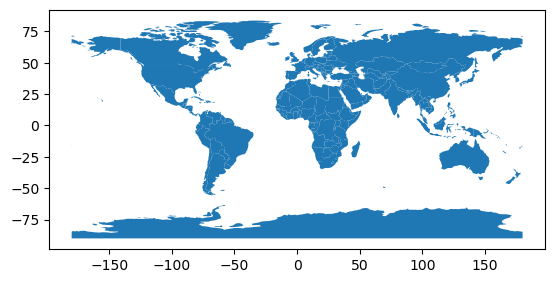

In [28]:
countries.plot()

In [37]:
eq.crs == countries.crs

True

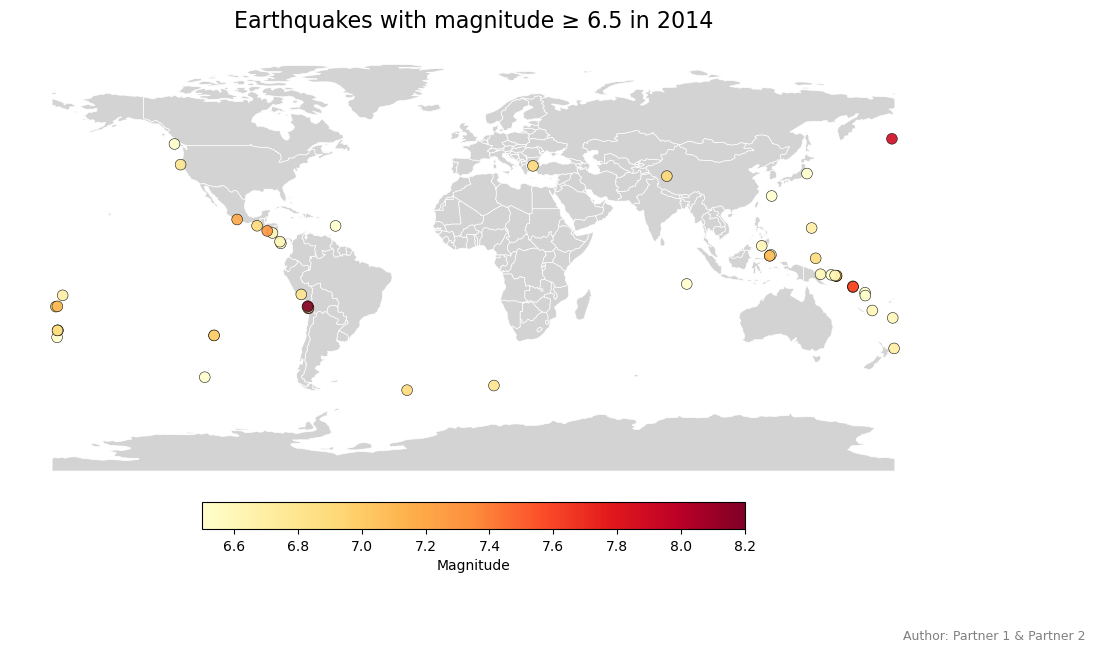

In [59]:
fig, ax = plt.subplots(figsize=(14, 7))

# Basemap: countries in light gray with white borders
countries.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.5)

# Earthquakes colored by magnitude
eq.plot(
    ax=ax,
    column='mag',
    cmap='YlOrRd',
    markersize=60,
    edgecolor='black',
    linewidth=0.4,
    alpha=0.9,
    legend=True,
    legend_kwds={'label': 'Magnitude', 'orientation': 'horizontal', 'shrink': 0.5, 'pad': 0.02}
)

ax.set_title('Earthquakes with magnitude ≥ 6.5 in 2014', fontsize=16, pad=12)
ax.set_axis_off()

# Section 4 of the discussion: each partner adds their name on their own branch.
plt.figtext(0.95, 0.03, 'Author: Partner 1 & Partner 2', ha='right', fontsize=9, color='gray')

plt.show()